In [1]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_error
)

from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    AdaBoostRegressor
)

from sklearn.svm import SVR

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.model_selection import RandomizedSearchCV

from catboost import CatBoostRegressor
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("data/student.csv")

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [6]:
print(df.columns.tolist())

['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


In [7]:
df.columns = df.columns.str.strip()

In [9]:
print("math score" in df.columns)

True


In [10]:
X = df.drop(columns=["math score"])
y = df["math score"]

In [11]:
X.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75


In [12]:
y

0      72
1      69
2      90
3      47
4      76
       ..
995    88
996    62
997    59
998    68
999    77
Name: math score, Length: 1000, dtype: int64

In [13]:
print("Categories in 'gender' variable:" ,end=" ")
print(df["gender"].unique())
print("Categories in 'race/ethnicity' variable:" ,end=" ")
print(df["race/ethnicity"].unique())
print("Categories in 'parental level of education' variable:" ,end=" ")
print(df["parental level of education"].unique())
print("Categories in 'lunch' variable:" ,end=" ")
print(df["lunch"].unique())
print("Categories in 'test preparation course' variable:" ,end=" ")
print(df["test preparation course"].unique())

Categories in 'gender' variable: <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race/ethnicity' variable: <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in 'parental level of education' variable: <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable: <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test preparation course' variable: <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [14]:
num_features=X.select_dtypes(exclude="object").columns
cat_features=X.select_dtypes(include="object").columns

from sklearn.preprocessing import OneHotEncoder , StandardScaler
from sklearn.compose import ColumnTransformer

numeric_transformer=StandardScaler()
oh_transformer=OneHotEncoder()
preprocessor=ColumnTransformer(
  [
    ("OneHotEncoder",oh_transformer ,cat_features),
    ("StandardScaler",numeric_transformer,num_features),
  ]
)

In [15]:
X=preprocessor.fit_transform(X)

In [16]:
X.shape

(1000, 19)

In [17]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train,y_test=train_test_split(X,y , test_size=0.2 , random_state=42)
X_train.shape , X_test.shape

((800, 19), (200, 19))

In [18]:
from sklearn.metrics import r2_score
def evaluate_model(true , predict):
  mae=mean_absolute_error(true , predict)
  mse=mean_squared_error(true , predict)
  rmse=np.sqrt(mse)
  r2_square=r2_score(true , predict)
  return mae , rmse , r2_square

In [24]:
models={
  "Linear Regression":LinearRegression(),
  "Lasso":Lasso(),
  "Ridge":Ridge(),
  "K-Neighbours Regressor":KNeighborsRegressor(),
  "Decision Tree":DecisionTreeRegressor(),
  "Random Forest":RandomForestRegressor(),
  "XGB Regressor":XGBRegressor(),
  "CatBoost Regressor":CatBoostRegressor(verbose=False),
  "AdaBoost Regressor":AdaBoostRegressor()

}
model_list=[]
r2_list=[]

for i in range(len(list(models))):
  model=list(models.values())[i]
  model.fit(X_train , y_train)

  y_train_pred=model.predict(X_train)
  y_test_pred=model.predict(X_test)

  model_train_mae ,model_train_rmse,model_train_r2=evaluate_model(y_train , y_train_pred)
  model_test_mae ,model_test_rmse,model_test_r2=evaluate_model(y_test , y_test_pred)

  print(list(models.keys())[i])
  model_list.append(list(models.keys())[i])
  r2_list.append(model_test_r2)
  
  print("Model perfomance for training set...")
  print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
  print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
  print("- R2 Score: {:.4f}".format(model_train_r2))

  print("--------------------------------------")
  print("Model perfomance for testing set...")
  print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
  print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
  print("- R2 Score: {:.4f}".format(model_test_r2))

  print("="*30)
  print('\n')



Linear Regression
Model perfomance for training set...
- Root Mean Squared Error: 5.3231
- Mean Absolute Error: 4.2667
- R2 Score: 0.8743
--------------------------------------
Model perfomance for testing set...
- Root Mean Squared Error: 5.3940
- Mean Absolute Error: 4.2148
- R2 Score: 0.8804


Lasso
Model perfomance for training set...
- Root Mean Squared Error: 6.5938
- Mean Absolute Error: 5.2063
- R2 Score: 0.8071
--------------------------------------
Model perfomance for testing set...
- Root Mean Squared Error: 6.5197
- Mean Absolute Error: 5.1579
- R2 Score: 0.8253


Ridge
Model perfomance for training set...
- Root Mean Squared Error: 5.3233
- Mean Absolute Error: 4.2650
- R2 Score: 0.8743
--------------------------------------
Model perfomance for testing set...
- Root Mean Squared Error: 5.3904
- Mean Absolute Error: 4.2111
- R2 Score: 0.8806


K-Neighbours Regressor
Model perfomance for training set...
- Root Mean Squared Error: 5.7077
- Mean Absolute Error: 4.5167
- R2 S

In [25]:
pd.DataFrame(list(zip(model_list,r2_list)) , columns=['model name' ,'R2_score']).sort_values(by=['R2_score'],ascending=False)

,model name,R2_score
2,Ridge,0.880593
0,Linear Regression,0.880433
8,AdaBoost Regressor,0.857430
7,CatBoost Regressor,0.851632
5,Random Forest,0.851627
6,XGB Regressor,0.827797
1,Lasso,0.825320
3,K-Neighbours Regressor,0.783813
4,Decision Tree,0.748950


In [26]:
lin_model=LinearRegression(fit_intercept=True)
lin_model=lin_model.fit(X_train ,y_train)
y_pred=lin_model.predict(X_test)
score=r2_score(y_test , y_pred)*100
print("Accuracy of the model is %.2f"%score)

Accuracy of the model is 88.04


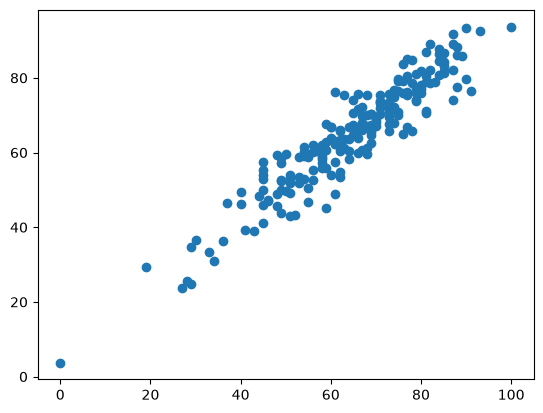

In [27]:
plt.scatter(y_test , y_pred)

In [28]:
pred_df=pd.DataFrame({'Actual Value':y_test , 'Predicted Value':y_pred , 'Difference':y_test-y_pred})

In [29]:
pred_df

,Actual Value,Predicted Value,Difference
521,91,76.387970,14.612030
737,53,58.885970,-5.885970
740,80,76.990265,3.009735
660,74,76.851804,-2.851804
411,84,87.627378,-3.627378
...,...,...,...
408,52,43.409149,8.590851
332,62,62.152214,-0.152214
208,74,67.888395,6.111605
613,65,67.022287,-2.022287
